In [1]:
import optimisation_activity
import OA_analysis
import pandas as pd
import pickle
import numpy as np
import os
import SimpleITK as sitk
import functions
import matplotlib.pyplot as plt
%load_ext autoreload
%autoreload 2

In [2]:
patients=["p11","p15", "p24", "p32", "p33", "p17", "p23", "p25",  "p28","p31", "p13", "p12"]
tumours= {"p24":[11,12], "p25":[11, 12], "p15":[11, 12, 13, 14, 22, 23, 24, 25, 26, 27, 28], "p33":[11, 12], 
		   "p32":[11, 12, 13, 21, 22], "p23":[11, 12, 13, 14,22, 24, 25, 26], "p17":[11, 12, 13, 14, 22, 24, 25, 26],
		   "p31":[11, 12,13, 14, 22, 23, 24, 25, 26, 27], "p28":[11, 12, 13, 14, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31], 
           "p11":[23, 25, 26, 27, 28, 29], "p13":[11, 12], "p12":[11, 12, 13, 14]}

measured activities post-reconstruction


patient p11
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
(29, 1.166340968027346, 1.0948275552641442, 0.7574108292535394, 0.0)


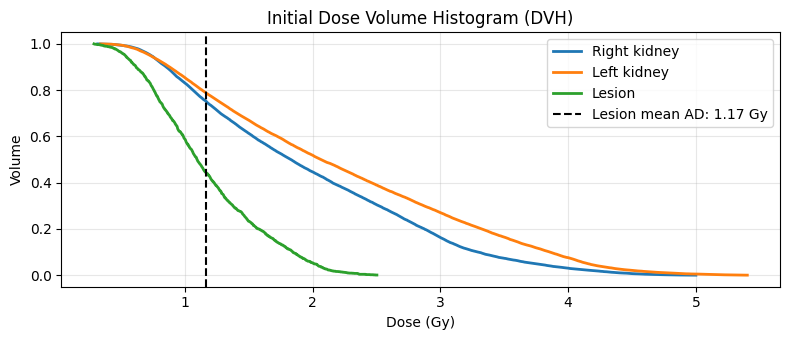

Kidney window: 7.40 - 18.68 GBq
Kidney window: 7.40 - 16.61 GBq


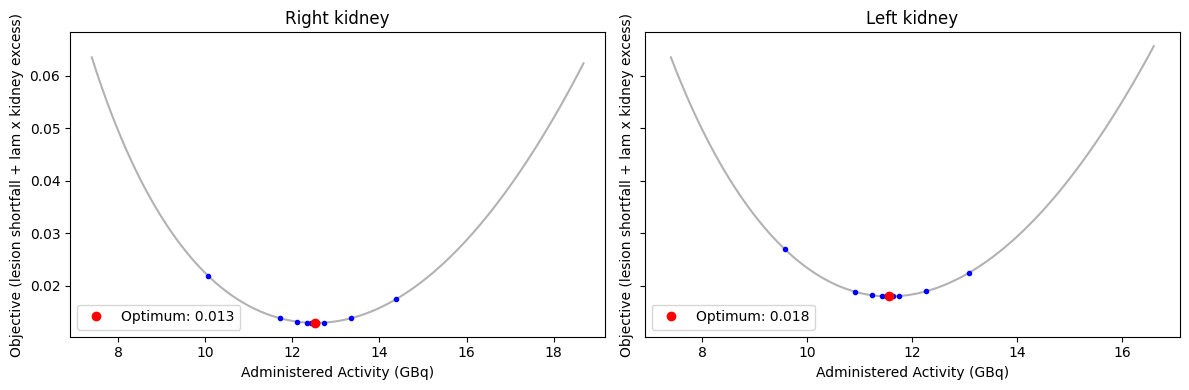

evaluating the 2 kidneys...
optimal activity: 11.56 GBq
Right kidney: 3.09 Gy
Left kidney: 3.48 Gy
lesion_mean: 2.51 Gy

patient p15
selected lesion: 28 with a mean absorbed dose of 28.764 Gy
selected lesion: 28 with a mean absorbed dose of 28.764 Gy
(28, 28.764476291135882, 13.765703742898388, 3.234758133455493, 0.7847222222222222)


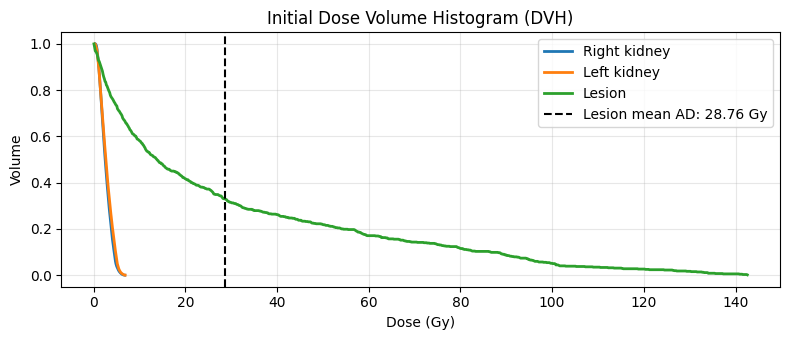

Kidney window: 7.40 - 13.74 GBq
Kidney window: 7.40 - 13.09 GBq


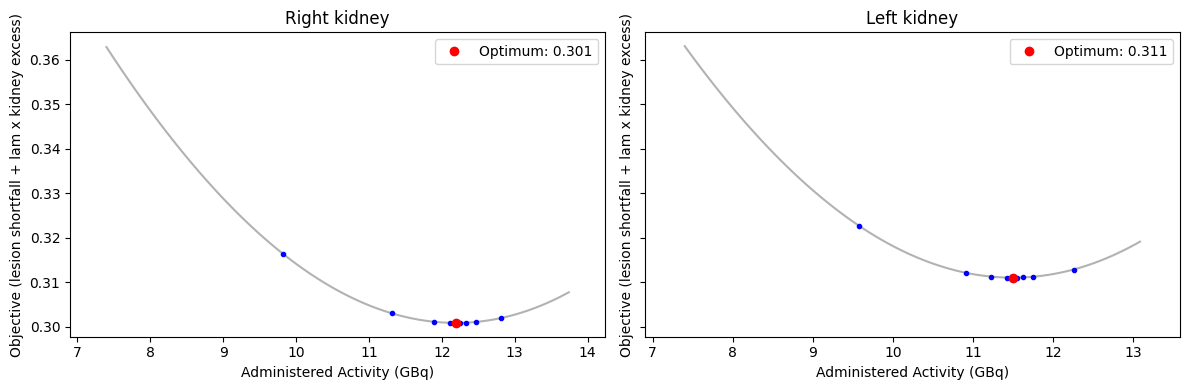

evaluating the 2 kidneys...
optimal activity: 11.50 GBq
Right kidney: 4.18 Gy
Left kidney: 4.39 Gy
lesion_mean: 24.93 Gy

patient p24
selected lesion: 12 with a mean absorbed dose of 3.261 Gy
selected lesion: 12 with a mean absorbed dose of 3.261 Gy
(12, 3.260604425754473, 2.5136396638571337, 1.096005421603777, 0.35874439461883406)


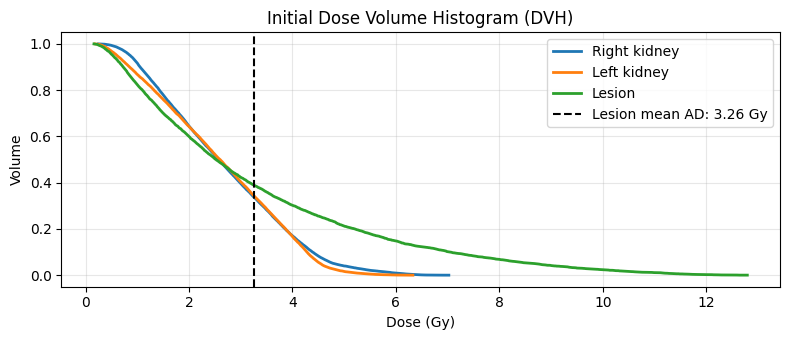

In [ ]:
activities=[]
lowest_lesions=[]
patients_done = []
otms= []
lesion_ids=[]
kid_optimised =[]
lesion_sizes = []
lesion_increase= []
init_lesions_list= []
opt_lesions_list= []
increase_lesions_list= []
true_increase_lesions_list=[]

lambdas={3.5:0.65, 4:0.55, 4.5:0.65, 5:0.45}

kidney_thresh=5 #Gy, threshold for mean absorbed dose in the kidney

for patient in patients:
    abdose_path= f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_abdose_2p21.nii"
    true_abdose_path = f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_abdose_2p21_true.nii"
    spect_24h_path= f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_lu177.nii"
    seg_path= f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes\\seg_spect_24h_w_tumours_resampled.nrrd"
    print("")
    print(f"patient {patient}")
    best_act, ad_lesion, best_otm, lesion_id, kid_value, resampled_seg=optimisation_activity.main(abdose_path, seg_path, 
                        spect_24h_path, 7400,tumours[patient], lam=lambdas[kidney_thresh], kidney_thresh= kidney_thresh)
    patients_done.append(patient)
    activities.append(best_act)
    lowest_lesions.append(ad_lesion)
    otms.append(best_otm)
    lesion_ids.append(lesion_id)
    kid_optimised.append(kid_value)

    seg_arr= sitk.GetArrayFromImage(functions.read_dicom(seg_path))
    mask= seg_arr== lesion_id
    lesion_size= mask.sum()*(np.prod(functions.read_dicom(seg_path).GetSpacing()))/1000
    lesion_sizes.append(lesion_size)
    init_lesions, opt_lesions, increase_lesions= optimisation_activity.lesion_increase(abdose_path, None, resampled_seg, 
                            tumours[patient], best_act)                    
    
    init_lesions, opt_lesions, true_increase_lesions= optimisation_activity.lesion_increase(abdose_path, true_abdose_path, resampled_seg, 
                            tumours[patient], best_act)  

    
    init_lesions_list.append(init_lesions)
    opt_lesions_list.append(opt_lesions)
    increase_lesions_list.append(increase_lesions)
    true_increase_lesions_list.append(true_increase_lesions)

pd.options.display.float_format = '{:.2f}'.format	
table = pd.DataFrame({"Patient": patients_done,
    "Opt. activity (GBq)": activities,
    "Optimum": otms,
    "Lowest lesion AD (Gy)": lowest_lesions,
    "Lesion size (mL)": lesion_sizes,
    "Initial lesion AD": init_lesions_list,
    "Optimised lesion AD": opt_lesions_list,
    "Increase (%)": increase_lesions_list,
    "True Increase (%)": true_increase_lesions_list}).round(2)

print(table.to_string(index=False))

print(f"\nMean activity: {table['Opt. activity (GBq)'].mean():.2f} GBq")
print(f"\nMean lesion increase: {table['True Increase (%)'].mean():.2f} %")

print(activities)

utilising the obtained optimised activities (with the "blind acquisition") in the ground truth activity map

In [11]:
def plot_histogram(patients, dict_cumulated_patients):

    right_kidney, right_std = [], []
    left_kidney, left_std = [], []

    for p in patients:
        data = dict_cumulated_patients.get(p, {})

        right_kidney.append(data.get(2, [np.nan, np.nan])[0])
        right_std.append(data.get(2, [np.nan, np.nan])[1])

        left_kidney.append(data.get(3, [np.nan, np.nan])[0])
        left_std.append(data.get(3, [np.nan, np.nan])[1])

    right_kidney = np.array(right_kidney, dtype=float)
    right_std = np.array(right_std, dtype=float)
    left_kidney = np.array(left_kidney, dtype=float)
    left_std = np.array(left_std, dtype=float)

    print("Valid right kidney doses:", np.isfinite(right_kidney).sum())
    print("Valid left kidney doses:", np.isfinite(left_kidney).sum())

    x = np.arange(len(patients))
    width = 0.38

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - width / 2, right_kidney, width,yerr=right_std, capsize=3,label="Right kidney")
    ax.bar(x + width / 2, left_kidney, width,yerr=left_std, capsize=3,label="Left kidney")

    ax.axhline(23, color="red", linestyle="--", label="23 Gy")

    ax.set_xticks(x)
    ax.set_xticklabels(patients, rotation=45, ha="right")
    ax.set_ylabel("Cumulative absorbed dose (Gy)")
    ax.set_title("Kidney absorbed dose over 6 cycles")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()



In [88]:
patients=["p11","p15", "p24", "p32", "p33", "p17", "p23", "p25","p28","p31", "p13", "p12"]
opt_activities=activities
dfs=[]
dict_cumulated_patients = {}
resampled_segs= []

run= "tumours"
print(f"running {run} mean AD:")

for i in range(len(patients)):
    patient= patients[i]
    opt_activity= opt_activities[i]
    lesion_id=lesion_ids[i]
    seg_path=  f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes\\seg_spect_24h_w_tumours_resampled.nrrd"
    abdose_path_sim= f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_abdose_2p21.nii"
    abdose_path_true= f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_abdose_2p21_true.nii"
    true_abdose, dict_patient_cumulated, resampled_seg= OA_analysis.main(opt_activity, opt_activity_2 = None,
                                                                         seg_path=seg_path,  abdose_path_true=abdose_path_true, 
                                                                         abdose_path= abdose_path_sim, tumour_keys= tumours[patient], run=run)
    dict_cumulated_patients[patient] = dict_patient_cumulated
    resampled_segs.append(resampled_seg)
    
    row = {"Patient ID": patient}
    for key, (init_dose, true_dose, increase) in true_abdose.items():
        if run == "kidneys":
            kidney = {2: "Kidney 2", 3: "Kidney 3"}.get(key, f"Key {key}")
            row[f"{kidney} Initial"] = round(init_dose, 2)
            row[f"{kidney} True Optimised"] = round(true_dose, 2)
            row[f"{kidney} Increase (%)"] = round(increase, 2)
        else:
            row[f"i {key} (%)"] = round(increase, 2)

    dfs.append(row)

df_all = pd.DataFrame(dfs)
print(df_all.to_csv(sep="\t", index=False, float_format="%.2f"))

running tumours mean AD:
Patient ID	i 23 (%)	i 25 (%)	i 26 (%)	i 27 (%)	i 28 (%)	i 29 (%)	i 11 (%)	i 12 (%)	i 13 (%)	i 14 (%)	i 22 (%)	i 24 (%)	i 21 (%)	i 30 (%)	i 31 (%)
p11	167.53	214.26	110.69	204.67	148.02	152.73									
p15	113.39	166.91	111.49	160.90	178.98		-15.98	24.18	18.16	-0.58	38.96	7.64			
p24							3.06	12.95							
p32							100.96	85.72	159.67		253.52		296.02		
p33							91.28	107.53							
p17		9687.90	25921765.53				76.91	409.48	45.93	-116.96	41.58	95.71			
p23			167.37				-10.98	-13.20	30.38	285.63	1379.79	437.63			
p25							61.31	18.78							
p28	41.89	443.70	54.20	60.46	773.14	1289063316050879232.00	81.45	492.12	71.85	542.14	64.15	172.32			232.88
p31	199.29	13.84	3.78	71.21			7.18	23.92	6.62	86.00	4.13	0.34			
p13							67.44	191.01							
p12							489.90	348.58	530.09	532.11					



6 cycle evaluation

In [18]:
activities_cycle_1=[]
activities_others=[]
patients_done = []
lesion_ids=[]
resampled_segs= []
dfs=[]
dict_cumulated_patients={}

run= "kidneys"
lambdas={3.5:0.65, 4:0.55, 4.5:0.65, 5:0.45}
kidney_thresh_tested= [4.5, 4]
#kidney_thresh_tested= [4.5, 3.5]
#kidney_thresh_tested= [5, 3.5]
#kidney_thresh_tested= [5, 4]

threshold_scenarios = {"4.5 → 4.0 Gy": (4.5, 4.0), "4.0 → 4.0 Gy": (4.0, 4.0), "5.0 → 3.5 Gy": (5.0, 3.5), "5.0 → 4.0 Gy": (5.0, 4.0)}

for patient in patients:
    abdose_path= f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_abdose_2p21.nii"
    spect_24h_path= f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_lu177.nii"
    seg_path= f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes\\seg_spect_24h_w_tumours_resampled.nrrd"
    print("")
    print(f"patient {patient}")
    for i in range(len(kidney_thresh_tested)):
        kidney_thresh= kidney_thresh_tested[i]
        lam= lambdas[kidney_thresh]
        best_act, ad_lesion, best_otm, lesion_id, kid_value, resampled_seg=optimisation_activity.main(abdose_path, seg_path, 
							spect_24h_path, 7400,tumours[patient], lam=lambdas[kidney_thresh], plot= False, prints= False, 
                            kidney_thresh= kidney_thresh)
        lesion_ids.append(lesion_id)
        if i == 0 :
            activities_cycle_1.append(best_act)
        else:
            activities_others.append(best_act)

for i in range(len(patients)):
    patient= patients[i]
    opt_activity_1= activities_cycle_1[i]
    opt_activity_2= activities_others[i]
    
    lesion_id=lesion_ids[i]
    seg_path=  f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes\\seg_spect_24h_w_tumours_resampled.nrrd"
    abdose_path_sim= f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_abdose_2p21.nii"
    abdose_path_true= f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_abdose_2p21_true.nii"
    true_abdose, dict_patient_cumulated, resampled_seg= OA_analysis.main(opt_activity_1, opt_activity_2, 
                                                                        seg_path, abdose_path_true, abdose_path_sim, 
                                                                        tumours[patient], run)
    dict_cumulated_patients[patient] = dict_patient_cumulated
    resampled_segs.append(resampled_seg)



patient p11
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
evaluating the 2 kidneys...
optimal activity: 10.43 GBq
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
selected lesion: 29 with a mean absorbed dose of 1.166 Gy
evaluating the 2 kidneys...
optimal activity: 9.82 GBq

patient p15
selected lesion: 28 with a mean absorbed dose of 28.764 Gy
selected lesion: 28 with a mean absorbed dose of 28.764 Gy
evaluating the 2 kidneys...
optimal activity: 9.68 GBq
selected lesion: 28 with a mean absorbed dose of 28.764 Gy
selected lesion: 28 with a mean absorbed dose of 28.764 Gy
evaluating the 2 kidneys...
optimal activity: 8.93 GBq

patient p24
selected lesion: 12 with a mean absorbed dose of 3.261 Gy
selected lesion: 12 with a mean absorbed dose of 3.261 Gy
evaluating the 2 kidneys...
optimal activity: 10.25 GBq
selected lesion: 12 with a mean absorbed dose of 3.261 Gy
selected lesion: 12 with a mean absorbed d

 right kidney cumulative mean absorbed dose: 19.33 Gy
 left kidney cumulative mean absorbed dose: 19.43 Gy

mean cumulative mean absorbed dose 19.38 Gy
min cumulative mean absorbed dose 13.74 Gy
max cumulative mean absorbed dose 23.52 Gy
Valid right kidney doses: 12
Valid left kidney doses: 11


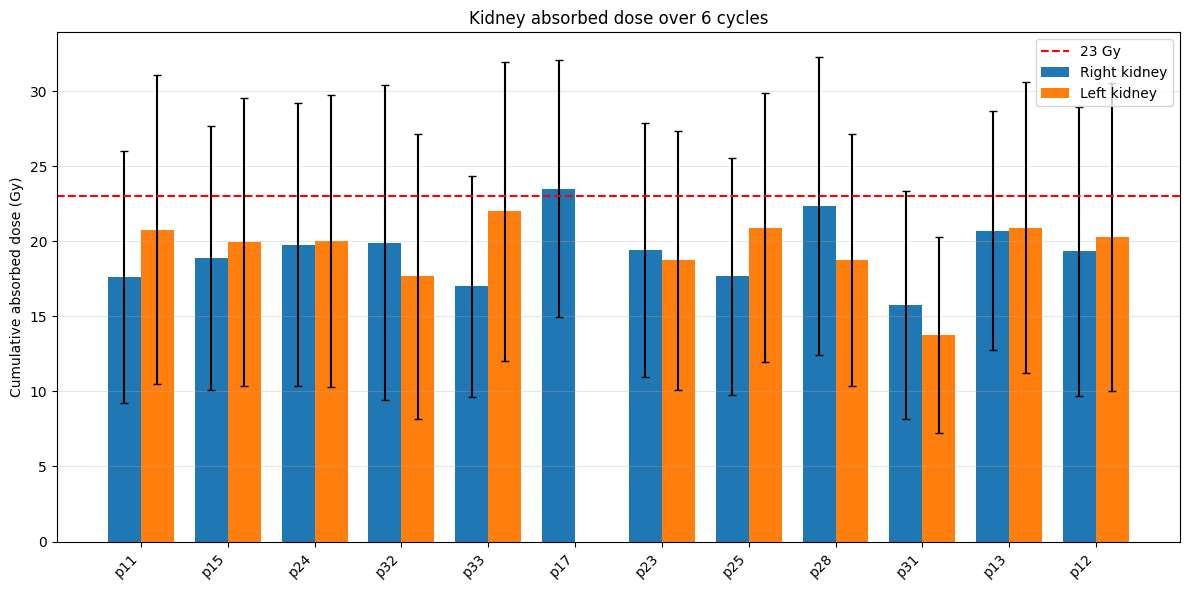

In [19]:
right_kidney = [dict_cumulated_patients[p].get(2, [np.nan, np.nan])[0] for p in patients]
print(f" right kidney cumulative mean absorbed dose: {np.mean(right_kidney) :.2f} Gy")
right_std = [dict_cumulated_patients[p].get(2, [np.nan, np.nan])[1] for p in patients]
left_kidney = [dict_cumulated_patients[p].get(3, [np.nan, np.nan])[0] for p in patients]
print(f" left kidney cumulative mean absorbed dose: {np.nanmean(left_kidney) :.2f} Gy")
left_std = [dict_cumulated_patients[p].get(3, [np.nan, np.nan])[1] for p in patients]

total_kidneys= right_kidney + left_kidney
print("")
print(f"mean cumulative mean absorbed dose {np.nanmean(total_kidneys) :.2f} Gy")
print(f"min cumulative mean absorbed dose {np.nanmin(total_kidneys) :.2f} Gy")
print(f"max cumulative mean absorbed dose {np.nanmax(total_kidneys) :.2f} Gy")

plot_histogram(patients, dict_cumulated_patients)


metrics

mean_kidney- correlation = -0.825, p_value= 0.001
median_kidney- correlation = -0.804, p_value= 0.002
mean_lesion- correlation = -0.371, p_value= 0.236
median_lesion- correlation = -0.406, p_value= 0.191
mean_ratio- correlation = 0.154, p_value= 0.633
median_ratio- correlation = 0.224, p_value= 0.484


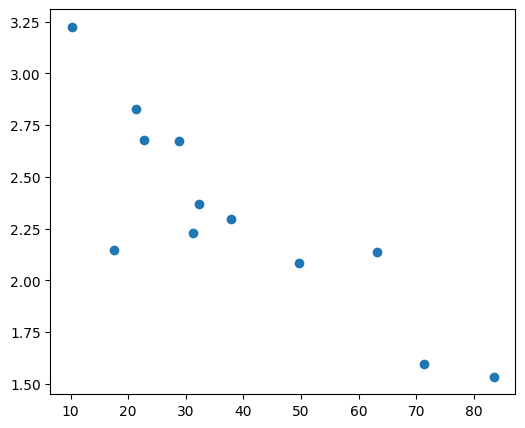

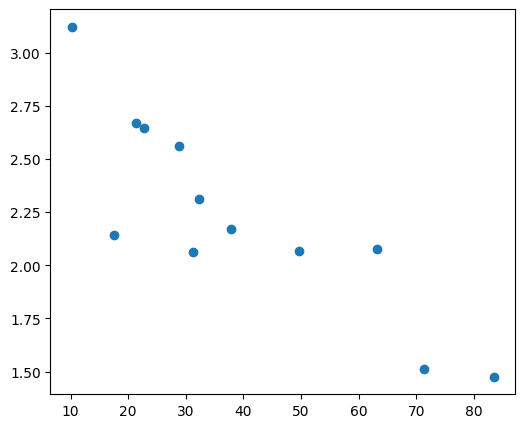

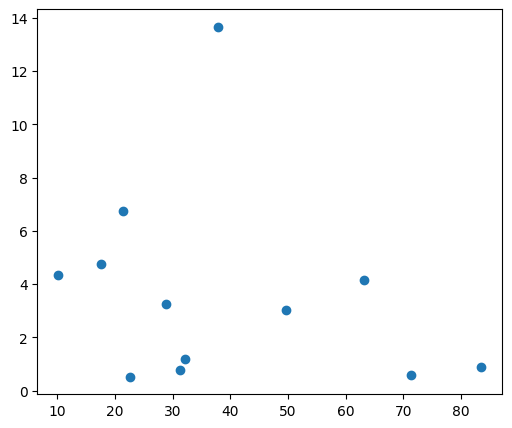

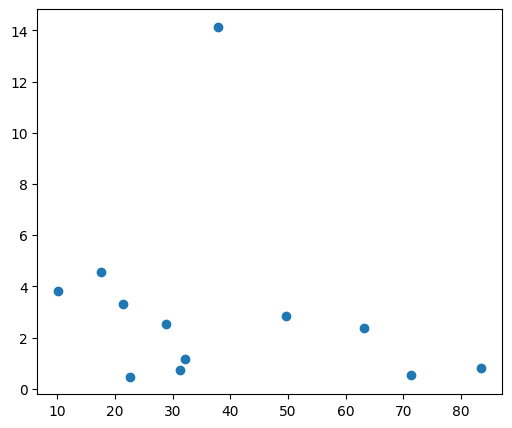

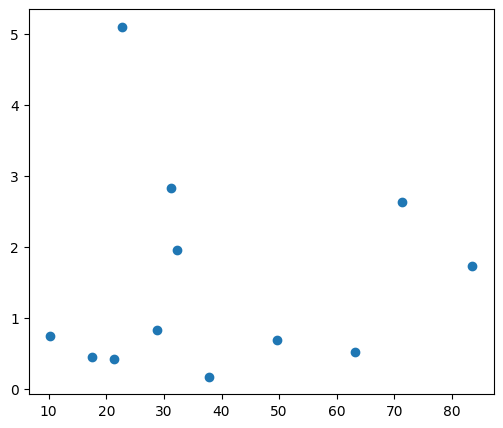

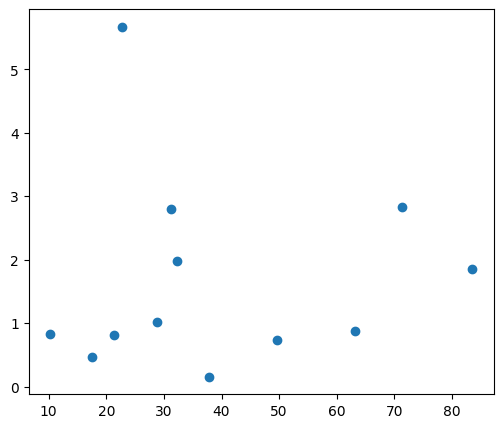

In [30]:
abdose_paths=[f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_abdose_2p21.nii" for patient in patients]
OA_analysis.correlations(patients, opt_activities, abdose_paths, resampled_segs, lesion_ids, kid_optimised)


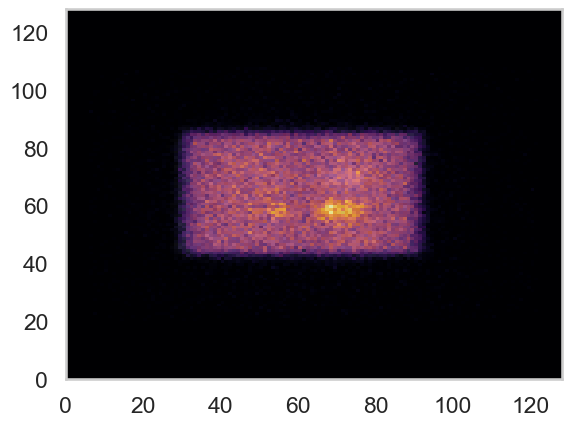

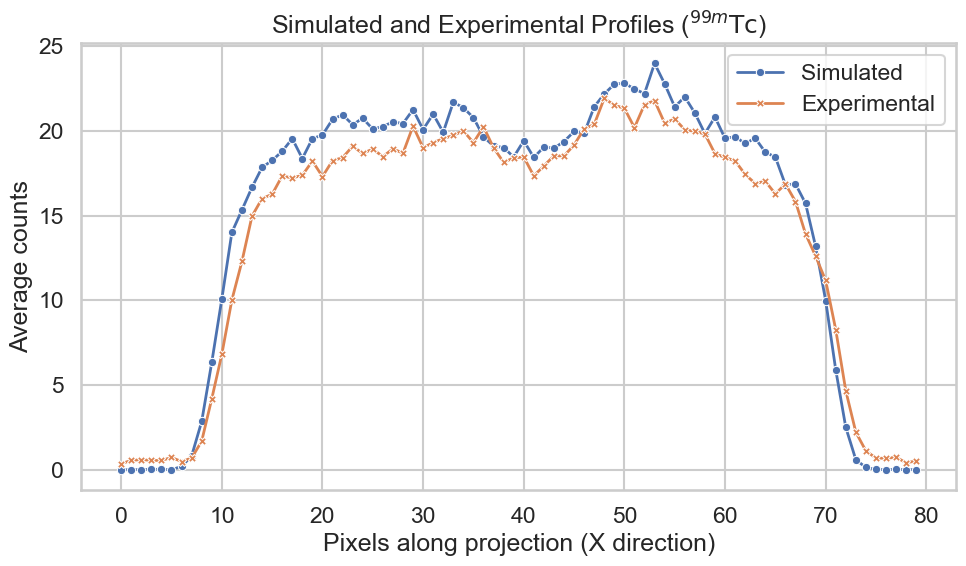

In [187]:
import seaborn as sns
from scipy.ndimage import shift
import sys
import functions
import SimpleITK as sitk
from pytomography.io.SPECT import simind
import torch

simind_projections_lu= "C:\\simind\\phantom_study\\2oteste_lu\\teste_mesa_tot_w2.h00"
simind_projections_lu = "F:\\tese_mestrado\\2_phantom_study\\2oteste_lu\\teste_mesa_tot_w2.h00"
fc_projections_lu= "C:\\simind\\phantom_study\\FC_results\\177Lu\\spect_projecoes_208"
fc_projections_lu= "F:\\tese_mestrado\\2_phantom_study\\FC_results\\177Lu\\spect_projecoes_208"

simind_projections_tc= "C:\\simind\\phantom_study\\teste_cr_tc99m\\teste_tc_tot_w2.h00"
simind_projections_tc ="F:\\tese_mestrado\\2_phantom_study\\teste_cr_tc99m\\teste_tc_tot_w2.h00"
fc_projections_tc="C:\\simind\\phantom_study\\FC_results\\Tc99m\\spect_nema_tc.dcm"
fc_projections_tc= "F:\\tese_mestrado\\2_phantom_study\\FC_results\\Tc99m\\spect_nema_tc.dcm"

simind_recon_lu= "C:\\simind\\phantom_study\\2oteste_lu\\nema_recon_3i_16s_teste2.nii"
fc_recon_lu= "C:\\simind\\phantom_study\\FC_results\\177Lu\\calibrated_lu_as_16s.nii"

simind_recon_tc= "C:\\simind\\phantom_study\\teste_cr_tc99m\\nema_recon_3i_16s_2.nii"
fc_recon_tc= "C:\\simind\\phantom_study\\FC_results\\Tc99m\\tc_ast_3i_16_inverted.nrrd"


time= 15
activity_lu= 518.84
activity_tc= 220.5327

#ler imagem simind
def simind_image(simind_path):
    simind_image= functions.read_dicom(simind_path)
    simind_array= sitk.GetArrayFromImage(simind_image)
    return simind_array

#ler imagem fc
def exp_image(fc_path):
    fc_image= functions.read_dicom(fc_path)
    fc_array= sitk.GetArrayFromImage(fc_image)
    return fc_array

def projection_analysis(simind_projections, fc_projections):
    index= 63
    simind_array= simind.get_projections(simind_projections)
    simind_array= torch.poisson(simind_array*time)
    simind_array= simind_array.cpu().numpy()
    if index<=63:
        level= 4
    else:
        level=-4

    shifted= shift(simind_array, shift=(0, -3, 0), mode='constant', cval=0)
    fc_array= exp_image(fc_projections)

    proj_simind = shifted[index,20:100, 20:100]
    proj_fc= fc_array[index,20:100, 20:100]

    plt.pcolormesh(shifted[index].T, cmap='Greys_r')
    plt.pcolormesh(fc_array[index], cmap='inferno', alpha=0.7)
    plt.show()

    profile1 = np.mean(proj_simind, axis=1)
    profile2 = np.mean(proj_fc, axis=0)
    x = np.arange(profile1.shape[0])

    sns.set(style="whitegrid", context="talk")
    df = pd.DataFrame({'Pixel': np.tile(x, 2),'Counts': np.concatenate([profile1, profile2]),'Type': ['Simulated'] * len(profile1) + ['Experimental'] * len(profile2)})
    plt.figure(figsize=(10, 6))
    sns.lineplot(data=df, x='Pixel', y='Counts', hue='Type', style='Type',markers=True, dashes=False, linewidth=2, markersize=6)
    plt.xlabel('Pixels along projection (X direction)')
    plt.ylabel('Average counts')
    plt.title(r'Simulated and Experimental Profiles ($^{99m}\mathrm{Tc}$)')
    plt.legend(title=None)
    plt.tight_layout()
    plt.show()

projection_analysis(simind_projections_tc,fc_projections_tc)


In [ ]:
activities_cycle_1=[]
activities_others=[]
patients_done = []
lesion_ids=[]
resampled_segs= []
dfs=[]
dict_cumulated_patients={}

run= "kidneys"
lambdas={3.5:0.65, 4:0.55, 4.5:0.65, 5:0.45}
threshold_scenarios = {"4.5 → 4.0 Gy": (4.5, 4.0), "4.0 → 4.0 Gy": (4.0, 4.0), "5.0 → 3.5 Gy": (5.0, 3.5), "5.0 → 4.0 Gy": (5.0, 4.0)}
all_results = []
run = "kidneys"

for patient in patients:

    abdose_path = (f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_abdose_2p21.nii")
    spect_24h_path = (f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_lu177.nii")
    seg_path=  f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes\\seg_spect_24h_w_tumours_resampled.nrrd"
    abdose_path_sim= f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_abdose_2p21.nii"
    abdose_path_true= f"F:\\champalimaud\\Ac225\\patients_phantoms\\{patient}\\recon_volumes_1\\lu177\\{patient}_abdose_2p21_true.nii"
    
    print(f"\n========== Patient {patient} ==========")

    for scenario, (thresh_1, thresh_other) in threshold_scenarios.items():
        print(f"\nScenario: {scenario}")
        act_1, ad_lesion_1, obj_1, lesion_id, kid_value_1, seg = (optimisation_activity.main(abdose_path,seg_path,spect_24h_path,
                7400,tumours[patient],lam=lambdas[thresh_1],plot=False,prints=False,kidney_thresh=thresh_1))
        act_other, ad_lesion_2, obj_2, lesion_id_2, kid_value_2, seg = (
            optimisation_activity.main(abdose_path,seg_path,spect_24h_path,7400,tumours[patient],lam=lambdas[thresh_other],
                plot=False,prints=False,kidney_thresh=thresh_other))

        if lesion_id != lesion_id_2:
            raise ValueError(f"Different lesion IDs returned for {patient}, {scenario}")

        true_abdose, dict_patient_cumulated, resampled_seg = OA_analysis.main(act_1,act_other,seg_path,
            abdose_path_true,abdose_path,tumours[patient],run)

        all_results.append({"patient": patient,"scenario": scenario,"kidney_thresh_cycle1": thresh_1,
            "kidney_thresh_others": thresh_other,"lambda_cycle1": lambdas[thresh_1],"lambda_others": lambdas[thresh_other],
			"activity_cycle1": act_1,"activity_others": act_other,"objective_cycle1": obj_1,
            "objective_others": obj_2,"lesion_id": lesion_id, "dict_cumulated": dict_patient_cumulated})

        print(f"Activity cycle 1: {act_1:.3f} GBq")
        print(f"Activity others:  {act_other:.3f} GBq")
        print("Cumulative evaluation completed.")


========== Patient p11 ==========

Scenario: 4.5 → 4.0 Gy
selected lesion: 29 with a mean absorbed dose of 0.789 Gy
selected lesion: 29 with a mean absorbed dose of 0.789 Gy
evaluating the 2 kidneys...
optimal activity: 10.28 GBq
selected lesion: 29 with a mean absorbed dose of 0.789 Gy
selected lesion: 29 with a mean absorbed dose of 0.789 Gy
evaluating the 2 kidneys...
optimal activity: 9.71 GBq
Activity cycle 1: 10.283 GBq
Activity others:  9.708 GBq
Cumulative evaluation completed.

Scenario: 4.0 → 4.0 Gy
selected lesion: 29 with a mean absorbed dose of 0.789 Gy
selected lesion: 29 with a mean absorbed dose of 0.789 Gy
evaluating the 2 kidneys...
optimal activity: 9.71 GBq
selected lesion: 29 with a mean absorbed dose of 0.789 Gy
selected lesion: 29 with a mean absorbed dose of 0.789 Gy
evaluating the 2 kidneys...
optimal activity: 9.71 GBq
Activity cycle 1: 9.708 GBq
Activity others:  9.708 GBq
Cumulative evaluation completed.

Scenario: 5.0 → 3.5 Gy
selected lesion: 29 with a me

In [ ]:
os.makedirs("kidney_threshold_analysis", exist_ok=True)

with open("kidney_threshold_analysis/all_cumulative_results.pkl","wb") as f:
    pickle.dump(all_results, f)

df_results = pd.DataFrame([{k: v for k, v in result.items() if k != "dict_cumulated"} for result in all_results])
df_results.to_csv("kidney_threshold_analysis/optimization_results.csv",index=False)
print(df_results.round(3).to_string(index=False))

patient     scenario  kidney_thresh_cycle1  kidney_thresh_others  lambda_cycle1  lambda_others  activity_cycle1  activity_others  objective_cycle1  objective_others  lesion_id
    p11 4.5 → 4.0 Gy                   4.5                   4.0           0.65           0.55           10.283            9.708             0.023             0.031         29
    p11 4.0 → 4.0 Gy                   4.0                   4.0           0.55           0.55            9.708            9.708             0.031             0.031         29
    p11 5.0 → 3.5 Gy                   5.0                   3.5           0.45           0.65           11.367            8.758             0.014             0.047         29
    p11 5.0 → 4.0 Gy                   5.0                   4.0           0.45           0.55           11.367            9.708             0.014             0.031         29
    p15 4.5 → 4.0 Gy                   4.5                   4.0           0.65           0.55            9.732         

In [57]:
rows = []

for result in all_results:
    for kidney_id, values in result["dict_cumulated"].items():
        rows.append({
            "patient": result["patient"],
            "scenario": result["scenario"],
            "kidney_id": kidney_id,
            "total_Gy": values[0],
            "std_Gy": values[1],
        })

dose_df = pd.DataFrame(rows)

print(dose_df.head())

  patient      scenario  kidney_id   total_Gy     std_Gy
0     p11  4.5 → 4.0 Gy          2  17.421592   8.299890
1     p11  4.5 → 4.0 Gy          3  20.513977  10.168558
2     p11  4.0 → 4.0 Gy          2  17.251221   8.218723
3     p11  4.0 → 4.0 Gy          3  20.313364  10.069116
4     p11  5.0 → 3.5 Gy          2  16.335200   7.782317


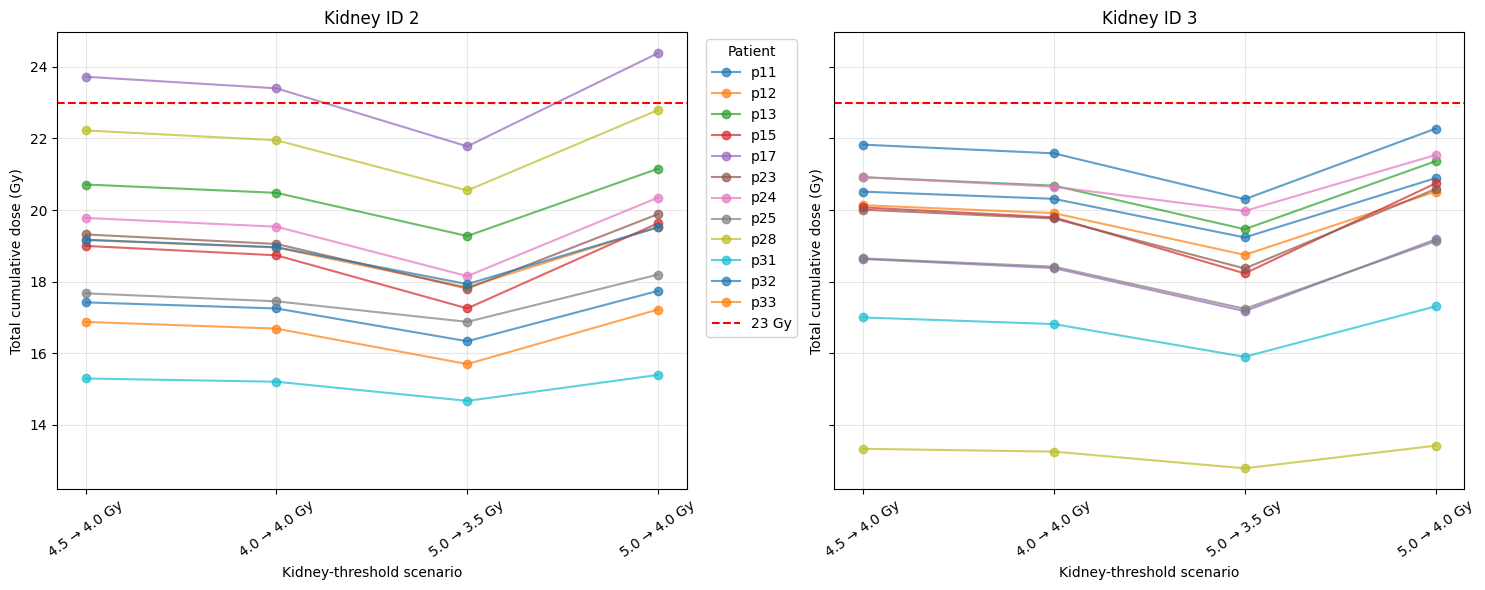

In [ ]:
fig, axes = plt.subplots(1, 2,figsize=(15, 6),sharey=True)

for ax, kidney_id in zip(axes, sorted(dose_df["kidney_id"].unique())):
    kidney_df = dose_df[dose_df["kidney_id"] == kidney_id]

    for patient, group in kidney_df.groupby("patient"):
        group = group.set_index("scenario").reindex(list(threshold_scenarios.keys()))

        ax.plot(group.index,group["total_Gy"], marker="o",alpha=0.7,label=str(patient))

    ax.set_title(f"Kidney ID {kidney_id}")
    ax.set_xlabel("Kidney-threshold scenario")
    ax.set_ylabel("Total cumulative dose (Gy)")
    ax.axhline(y=23,color="red",linestyle="--",linewidth=1.5,label="23 Gy")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(True, alpha=0.3)

    for patient, group in kidney_df.groupby("patient"):
        group = group.set_index("scenario").reindex(scenarios)

        # Mean dose with standard deviation as error bars
        ax.errorbar(scenarios,
            group["total_Gy"],
            yerr=group["std_Gy"],
            marker="o",
            capsize=4,
            linewidth=1.2,
            markersize=5,
            alpha=0.8,
            label=str(patient)
        )

axes[0].legend(title="Patient",bbox_to_anchor=(1.02, 1),loc="upper left")
plt.tight_layout()
plt.show()